# CMS Open Data: training-sample comparison

## Objective and scope

This notebook compares the shapes of eight event-level variables in four local training samples: Higgs, DY, Top, and WW. It reads scalar branches in chunks, reports data-quality counts, and draws superimposed unit-area histograms.

This is an exploratory plotting and validation notebook. It does not apply an H→WW event selection, calculate expected physics yields, or train a model. Sample roles and process identities are inferred from filenames pending mentor confirmation. The exact Higgs production mode and decay channel are not established by these files.

Run this notebook with the project root as the Jupyter working directory. It only reads ROOT input files. When executed, plots are saved under plots/training_comparison; that directory is created only by the plotting cell.

## Imports and configuration

The ROOT files contain an Events RNTuple, so Uproot reads them directly. The configured step size limits how much data is read at once. Bin edges and display ranges are explicit and can be adjusted after review.

Histograms are unweighted shapes normalized over valid events inside the displayed range. Counts outside that range remain in the diagnostic summary.

In [7]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import uproot

# Launch Jupyter with the project root as its working directory.
PROJECT_DIR = Path.cwd()
TREE_NAME = "Events"
STEP_SIZE = "100 MB"
BAD = -999.0
ANGLE_TOLERANCE = 1e-5
PLOT_DIR = PROJECT_DIR / "plots" / "training_comparison"

SAMPLES = {
    "Higgs": PROJECT_DIR / "Higgs-train.root",
    "DY": PROJECT_DIR / "DY-train.root",
    "Top": PROJECT_DIR / "Top-train.root",
    "WW": PROJECT_DIR / "WW-train.root",
}

# (low edge, high edge, number of bins); tune only after reviewing diagnostics.
VARIABLES = {
    "mll": {"title": "Dilepton invariant mass", "unit": "GeV",
            "range": (0.0, 300.0), "bins": 60,
            "description": "Invariant mass of the two selected leptons."},
    "mjj": {"title": "Dijet invariant mass", "unit": "GeV",
            "range": (0.0, 1000.0), "bins": 50,
            "description": "Invariant mass of the two highest-pT selected cleaned jets."},
    "mth": {"title": "Dilepton plus missing-momentum transverse-mass-like variable",
            "unit": "GeV", "range": (0.0, 500.0), "bins": 50,
            "description": "Starter-code formula using dilepton pT, missing pT, and their azimuthal separation."},
    "mtw2": {"title": "Subleading-lepton plus missing-momentum transverse mass",
             "unit": "GeV", "range": (0.0, 500.0), "bins": 50,
             "description": "Starter code calculates the subleading lepton plus missing-momentum transverse mass; it is not stransverse mass mT2."},
    "ptll": {"title": "Dilepton transverse momentum", "unit": "GeV",
             "range": (0.0, 500.0), "bins": 50,
             "description": "Transverse momentum of the summed dilepton four-vector."},
    "dphill": {"title": "Signed azimuthal difference between the leptons",
               "unit": "rad", "range": (-math.pi, math.pi), "bins": 32,
               "description": "Signed wrapped difference in lepton azimuth, expected in [-pi, pi]."},
    "nJet": {"title": "Input jet count", "unit": "jets",
             "range": (-0.5, 24.5), "bins": 25,
             "description": "Stored branch appears to be the original input jet count, not the cleaned selected-jet count."},
    "PuppiMET_pt": {"title": "Missing transverse momentum", "unit": "GeV",
                    "range": (0.0, 500.0), "bins": 50,
                    "description": "Magnitude of the PUPPI missing transverse momentum."},
}
BRANCHES = list(VARIABLES)
COLORS = {"Higgs": "tab:red", "DY": "tab:blue", "Top": "tab:green", "WW": "tab:orange"}
BIN_EDGES = {
    name: np.linspace(spec["range"][0], spec["range"][1], spec["bins"] + 1)
    for name, spec in VARIABLES.items()
}
# Integer-aligned bins centered on nJet = 0 through 24.
BIN_EDGES["nJet"] = np.arange(-0.5, 25.5, 1.0)

# Separate derived view; signed dphill and its plot remain unchanged.
ABS_DPHILL_KEY = "abs_dphill"
ABS_DPHILL_EDGES = np.linspace(0.0, math.pi, 33)


## Sample manifest and file/schema validation

The short labels are for readable legends only. Process identities are inferred from filenames. Do not infer a Higgs decay channel or production mode from the name alone.

This validation opens each file to inspect its Events object, entry count, and required branches. It reads ROOT metadata only; it does not scan event arrays.

In [8]:
def validate_samples(samples=SAMPLES, branches=BRANCHES, tree_name=TREE_NAME):
    """Check input files and required scalar branches without reading events."""
    manifest = {}
    for label, path in samples.items():
        if not path.is_file():
            raise FileNotFoundError(
                f"Missing {label} sample: {path}. Run this notebook with the project root as the working directory."
            )
        try:
            with uproot.open(path) as root_file:
                if tree_name not in root_file:
                    raise KeyError(
                        f"{path.name} has no {tree_name!r} object; available objects: {root_file.keys()}"
                    )
                events = root_file[tree_name]
                available = set(events.keys())
                missing = [branch for branch in branches if branch not in available]
                if missing:
                    raise KeyError(f"{path.name} is missing required branches: {missing}")
                manifest[label] = {
                    "path": path,
                    "entries": int(events.num_entries),
                    "object_class": type(events).__name__,
                    "branches": available,
                }
        except (OSError, ValueError) as exc:
            raise RuntimeError(f"Could not open ROOT input {path}: {exc}") from exc
    return manifest


sample_info = validate_samples()
for label, info in sample_info.items():
    print(
        f"{label}: {info['path'].name} | {info['object_class']} | "
        f"{info['entries']:,} events | all {len(BRANCHES)} plotted branches found"
    )


Higgs: Higgs-train.root | Model_ROOT_3a3a_RNTuple | 1,439,000 events | all 8 plotted branches found
DY: DY-train.root | Model_ROOT_3a3a_RNTuple | 21,849,377 events | all 8 plotted branches found
Top: Top-train.root | Model_ROOT_3a3a_RNTuple | 7,746,000 events | all 8 plotted branches found
WW: WW-train.root | Model_ROOT_3a3a_RNTuple | 1,011,000 events | all 8 plotted branches found


## Chunked histogram and data-quality helpers

One file is processed at a time. Each iteration reads only the eight scalar branches used here. For every variable the helper accumulates fixed-bin counts and counts of valid, sentinel, non-finite, physically invalid, zero-placeholder, underflow, and overflow values. Event arrays are discarded after each chunk.

A sentinel is counted separately from other invalid values. Underflow and overflow are computed from valid values, so they describe values excluded only by the chosen display range.

In [9]:
def classify_values(name, values):
    """Return validity masks and disjoint diagnostic counts for one branch."""
    values = np.asarray(values)
    if values.ndim != 1:
        raise ValueError(f"{name} must be a scalar event branch; got shape {values.shape}")

    finite = np.isfinite(values)
    sentinel = finite & (values == BAD)
    nonfinite = ~finite
    candidate = finite & ~sentinel

    negative = np.zeros(values.shape, dtype=bool)
    zero_placeholder = np.zeros(values.shape, dtype=bool)
    out_of_angle = np.zeros(values.shape, dtype=bool)
    non_integer = np.zeros(values.shape, dtype=bool)

    if name in {"mll", "mth", "mtw2", "ptll", "mjj", "PuppiMET_pt"}:
        negative = candidate & (values < 0)
    if name == "mjj":
        zero_placeholder = candidate & (values == 0)
    if name == "dphill":
        out_of_angle = candidate & (
            (values < -math.pi - ANGLE_TOLERANCE)
            | (values > math.pi + ANGLE_TOLERANCE)
        )
    if name == "nJet":
        non_integer = candidate & (values != np.floor(values))

    valid = candidate & ~negative & ~out_of_angle & ~non_integer
    if name == "mjj":
        # Preprocessing uses zero when fewer than two selected cleaned jets exist.
        valid &= ~zero_placeholder

    invalid = nonfinite | negative | out_of_angle | non_integer
    diagnostics = {
        "total": int(values.size),
        "valid": int(np.count_nonzero(valid)),
        "sentinel": int(np.count_nonzero(sentinel)),
        "nonfinite": int(np.count_nonzero(nonfinite)),
        "negative": int(np.count_nonzero(negative)),
        "out_of_angle": int(np.count_nonzero(out_of_angle)),
        "non_integer": int(np.count_nonzero(non_integer)),
        "zero_placeholder": int(np.count_nonzero(zero_placeholder)),
        "invalid": int(np.count_nonzero(invalid)),
        "underflow": 0,
        "overflow": 0,
        "observed_min": None,
        "observed_max": None,
        "valid_min": None,
        "valid_max": None,
    }
    finite_values = values[finite]
    if finite_values.size:
        diagnostics["observed_min"] = float(np.min(finite_values))
        diagnostics["observed_max"] = float(np.max(finite_values))
    if np.any(valid):
        diagnostics["valid_min"] = float(np.min(values[valid]))
        diagnostics["valid_max"] = float(np.max(values[valid]))
    return valid, diagnostics


def accumulate_absolute_angle(signed_values, result):
    """Accumulate |dphill| without changing the signed source values."""
    signed_values = np.asarray(signed_values)
    if signed_values.ndim != 1:
        raise ValueError(
            f"dphill must be a scalar event branch; got shape {signed_values.shape}"
        )

    finite = np.isfinite(signed_values)
    sentinel = finite & (signed_values == BAD)
    absolute_values = np.abs(signed_values)
    outside = finite & ~sentinel & (absolute_values > math.pi)
    valid = finite & ~sentinel & ~outside
    stats = result["stats"]
    stats["total"] += int(signed_values.size)
    stats["valid"] += int(np.count_nonzero(valid))
    stats["sentinel"] += int(np.count_nonzero(sentinel))
    stats["nonfinite"] += int(np.count_nonzero(~finite))
    stats["outside_abs_range"] += int(np.count_nonzero(outside))
    stats["invalid"] += int(np.count_nonzero(~finite) + np.count_nonzero(outside))

    # Range over finite, non-sentinel derived values, including out-of-range values.
    observed = absolute_values[finite & ~sentinel]
    if observed.size:
        low, high = float(np.min(observed)), float(np.max(observed))
        stats["observed_min"] = low if stats["observed_min"] is None else min(stats["observed_min"], low)
        stats["observed_max"] = high if stats["observed_max"] is None else max(stats["observed_max"], high)
    if np.any(valid):
        selected = absolute_values[valid]
        low, high = float(np.min(selected)), float(np.max(selected))
        stats["valid_min"] = low if stats["valid_min"] is None else min(stats["valid_min"], low)
        stats["valid_max"] = high if stats["valid_max"] is None else max(stats["valid_max"], high)
        edges = result["edges"]
        stats["underflow"] += int(np.count_nonzero(selected < edges[0]))
        stats["overflow"] += int(np.count_nonzero(selected > edges[-1]))
        result["counts"] += np.histogram(selected, bins=edges)[0]


def scan_file_histograms(path, branches=BRANCHES, bin_edges=BIN_EDGES,
                         step_size=STEP_SIZE, tree_name=TREE_NAME):
    """Stream one ROOT file and return histogram counts and diagnostics."""
    path = Path(path)
    if "dphill" not in branches:
        raise ValueError("The derived abs(dphill) histogram requires the dphill source branch")
    if not path.is_file():
        raise FileNotFoundError(f"ROOT file not found: {path}")

    results = {
        name: {
            "counts": np.zeros(len(bin_edges[name]) - 1, dtype=np.int64),
            "edges": np.asarray(bin_edges[name], dtype=float),
            "stats": {
                "total": 0, "valid": 0, "sentinel": 0, "nonfinite": 0,
                "negative": 0, "out_of_angle": 0, "non_integer": 0,
                "zero_placeholder": 0, "invalid": 0, "underflow": 0,
                "overflow": 0, "observed_min": None, "observed_max": None,
                "valid_min": None, "valid_max": None,
            },
        }
        for name in branches
    }
    results[ABS_DPHILL_KEY] = {
        "counts": np.zeros(len(ABS_DPHILL_EDGES) - 1, dtype=np.int64),
        "edges": ABS_DPHILL_EDGES.copy(),
        "stats": {
            "total": 0, "valid": 0, "sentinel": 0, "nonfinite": 0,
            "negative": 0, "out_of_angle": 0, "outside_abs_range": 0,
            "non_integer": 0, "zero_placeholder": 0, "invalid": 0,
            "underflow": 0, "overflow": 0,
            "observed_min": None, "observed_max": None,
            "valid_min": None, "valid_max": None,
        },
    }

    try:
        for chunk in uproot.iterate(
            {str(path): tree_name},
            expressions=list(branches),
            step_size=step_size,
            library="np",
        ):
            for name in branches:
                values = np.asarray(chunk[name])
                valid, current = classify_values(name, values)
                stats = results[name]["stats"]

                for key in (
                    "total", "valid", "sentinel", "nonfinite", "negative",
                    "out_of_angle", "non_integer", "zero_placeholder", "invalid",
                ):
                    stats[key] += current[key]

                for low_key, high_key in (
                    ("observed_min", "observed_max"),
                    ("valid_min", "valid_max"),
                ):
                    if current[low_key] is not None:
                        stats[low_key] = (
                            current[low_key] if stats[low_key] is None
                            else min(stats[low_key], current[low_key])
                        )
                        stats[high_key] = (
                            current[high_key] if stats[high_key] is None
                            else max(stats[high_key], current[high_key])
                        )

                selected = values[valid]
                edges = results[name]["edges"]
                stats["underflow"] += int(np.count_nonzero(selected < edges[0]))
                stats["overflow"] += int(np.count_nonzero(selected > edges[-1]))
                results[name]["counts"] += np.histogram(selected, bins=edges)[0]

            # Derive a separate absolute-angle view; do not modify chunk dphill.
            accumulate_absolute_angle(chunk["dphill"], results[ABS_DPHILL_KEY])
            del chunk, values, selected, valid, current
    except (OSError, ValueError, KeyError) as exc:
        raise RuntimeError(f"Failed while reading {path}: {exc}") from exc

    totals = {results[name]["stats"]["total"] for name in (*branches, ABS_DPHILL_KEY)}
    if len(totals) != 1:
        raise RuntimeError(f"Inconsistent event counts among branches in {path}: {totals}")
    return results


## Physics-variable definitions and validity rules

The definitions below are those documented in the existing preprocessing code and audited branch schema. They are not a substitute for mentor confirmation of the intended event selection.

- mll: invariant mass of the two selected leptons. Sentinel, non-finite, and negative values are excluded; negative values remain separately counted.
- mjj: invariant mass of two selected cleaned jets. Zero is reported separately because preprocessing uses it when fewer than two selected cleaned jets exist.
- mth: the starter code's transverse-mass-like quantity using dilepton pT, missing pT, and their azimuthal separation. It is not assumed to match another analysis's mT definition.
- mtw2: transverse mass of the subleading lepton plus missing transverse momentum. It is not standard stransverse mass mT2.
- ptll: transverse momentum of the summed dilepton four-vector.
- dphill: signed wrapped azimuthal difference between the selected leptons; values outside approximately [-pi, pi] are invalid.
- nJet: stored count branch, which appears to be the original input jet count rather than the cleaned selected-jet count. Zero remains valid.
- PuppiMET_pt: magnitude of missing transverse momentum; negative values are invalid.

Each variable is plotted using its own valid-event subset. No common event selection is imposed, so different variable plots need not contain the same events.

In [10]:
# Scan each training file once; do not load or concatenate complete datasets.
all_results = {}
for label, info in sample_info.items():
    print(f"Scanning {label}: {info['path'].name} ({info['entries']:,} events)")
    all_results[label] = scan_file_histograms(info["path"])
    print("  finished; chunk arrays released")


Scanning Higgs: Higgs-train.root (1,439,000 events)
  finished; chunk arrays released
Scanning DY: DY-train.root (21,849,377 events)
  finished; chunk arrays released
Scanning Top: Top-train.root (7,746,000 events)
  finished; chunk arrays released
Scanning WW: WW-train.root (1,011,000 events)
  finished; chunk arrays released


## Superimposed normalized distributions

Each panel overlays the four training samples on shared axes. Histograms are unweighted and normalized to unit area using valid events inside the displayed range. Underflow and overflow counts are shown in the diagnostic table, so the range choice can be revised.

These are shape comparisons, not expected event yields. The files contain no event weights, cross sections, or sum-of-weights metadata. No H→WW event selection is applied.

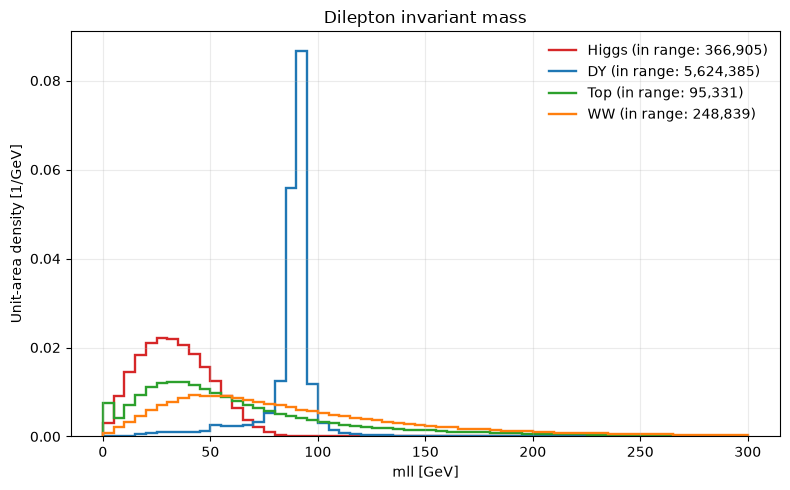

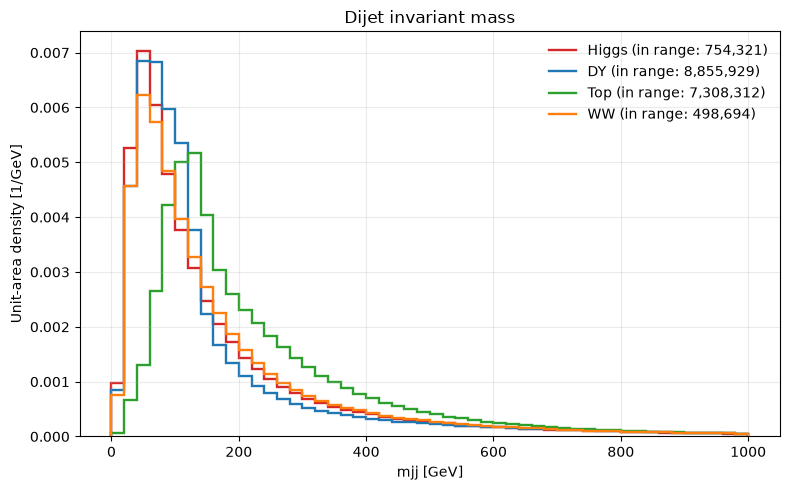

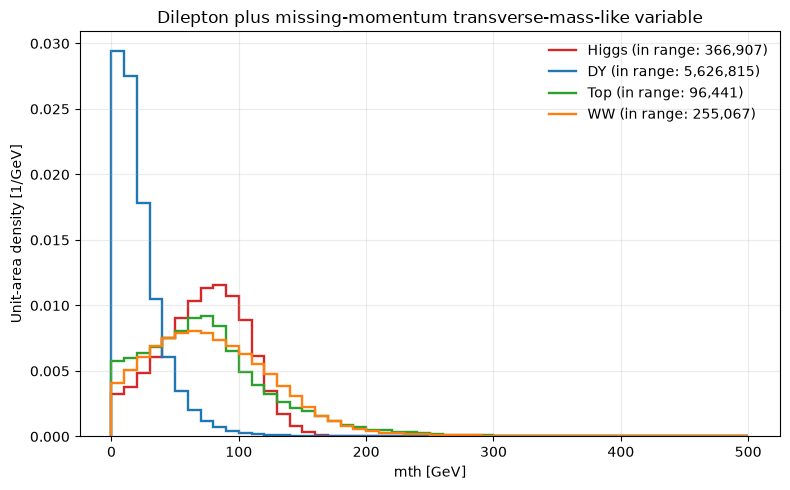

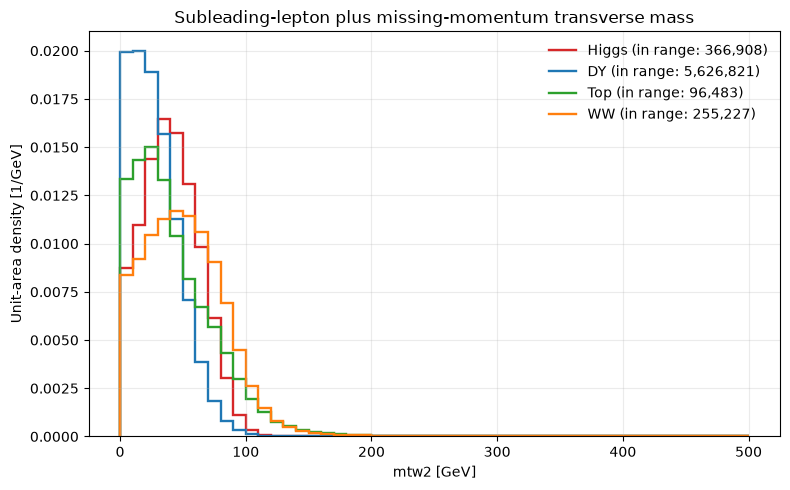

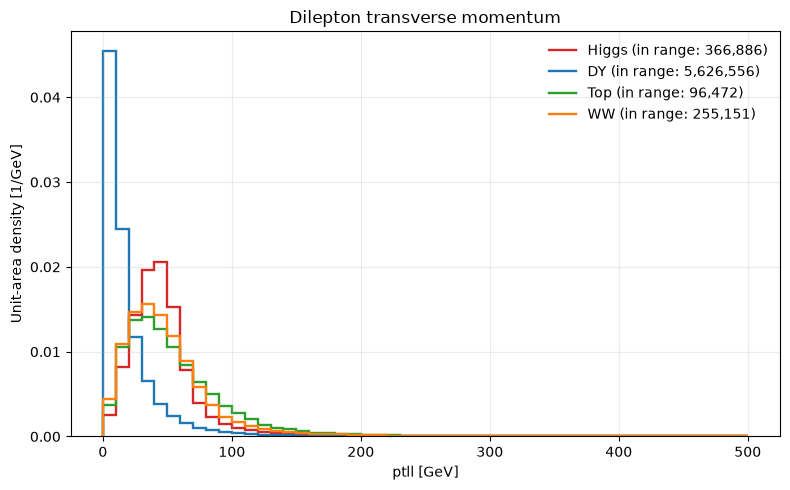

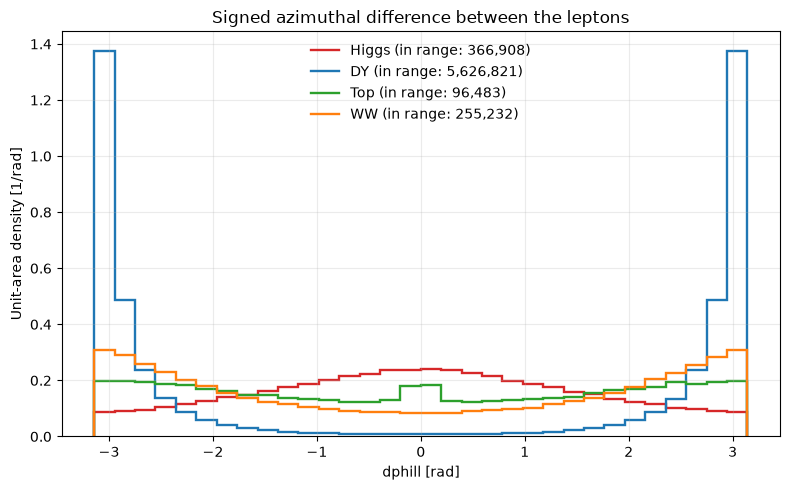

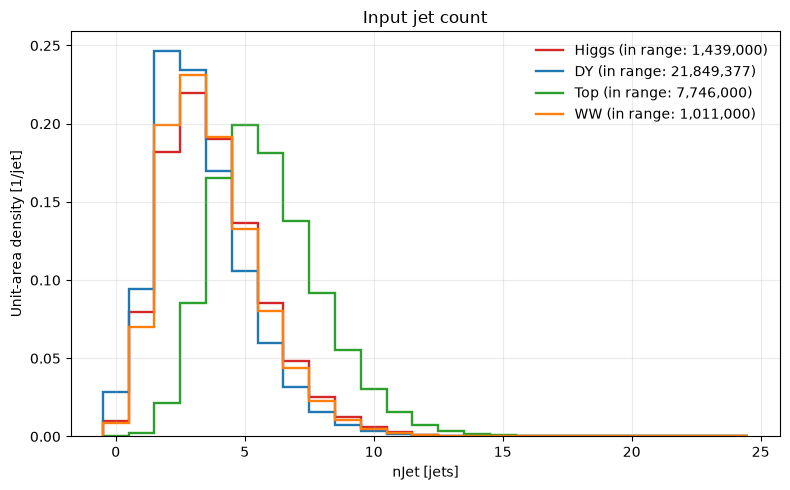

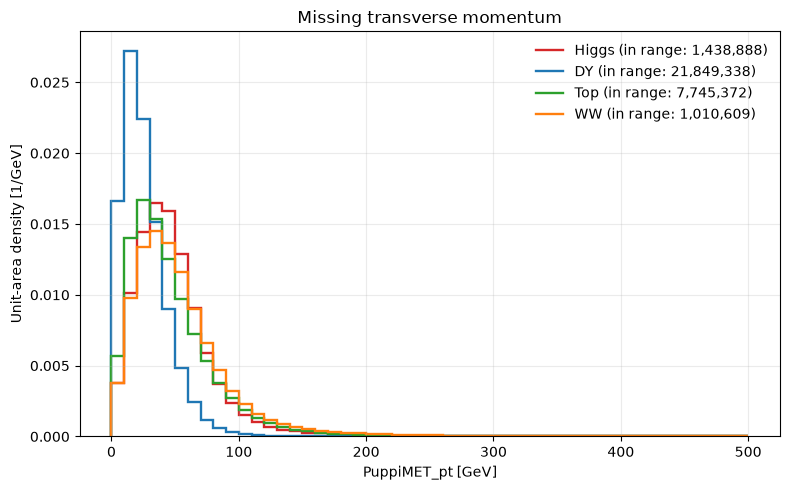

In [11]:
# The output directory is created only when this plotting cell is executed.
PLOT_DIR.mkdir(parents=True, exist_ok=True)

for name, spec in VARIABLES.items():
    fig, ax = plt.subplots(figsize=(8, 5))
    for label in SAMPLES:
        result = all_results[label][name]
        counts = result["counts"]
        edges = result["edges"]
        in_range_count = int(counts.sum())

        if in_range_count:
            density = counts / (in_range_count * np.diff(edges))
            ax.stairs(
                density, edges, color=COLORS[label], linewidth=1.7,
                label=f"{label} (in range: {in_range_count:,})",
            )
        else:
            ax.plot([], [], color=COLORS[label],
                    label=f"{label} (no in-range valid values)")

    unit = spec["unit"]
    ylabel = f"Unit-area density [1/{unit}]" if unit in {"GeV", "rad"} else "Unit-area density [1/jet]"
    ax.set_title(spec["title"])
    ax.set_xlabel(f"{name} [{unit}]")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.25)
    ax.legend(frameon=False)
    fig.tight_layout()
    fig.savefig(PLOT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## Additional derived visualization: abs(dphill)

This separate visualization is derived from the signed dphill source variable; it is not a newly measured quantity. The original signed branch, validity rule, and signed-angle plot remain unchanged. This uses the same four training files, chunk scan, sample colors, and unit-area normalization. The horizontal axis spans exactly 0 to pi. Finite, non-sentinel source values with abs(dphill) greater than pi are counted in outside_abs_range and excluded without clipping.

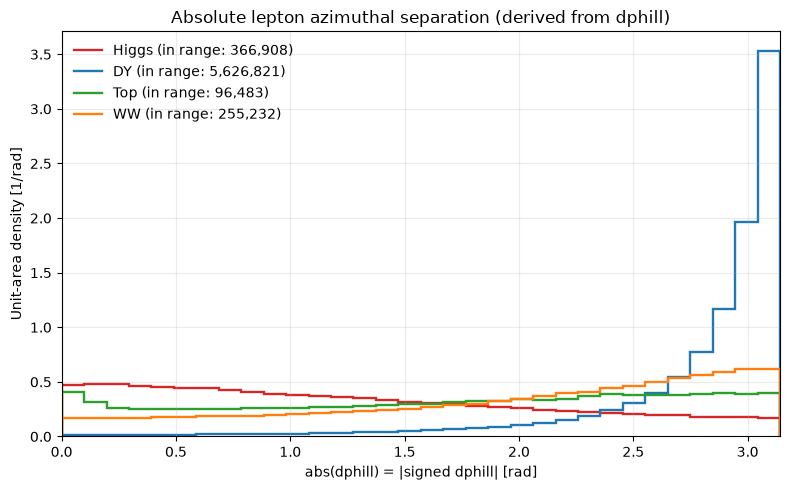

In [12]:
# Separate overlay of the absolute value derived from the signed dphill branch.
PLOT_DIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 5))
for label in SAMPLES:
    result = all_results[label][ABS_DPHILL_KEY]
    counts = result["counts"]
    edges = result["edges"]
    in_range_count = int(counts.sum())
    if in_range_count:
        density = counts / (in_range_count * np.diff(edges))
        ax.stairs(
            density, edges, color=COLORS[label], linewidth=1.7,
            label=f"{label} (in range: {in_range_count:,})",
        )
    else:
        ax.plot([], [], color=COLORS[label],
                label=f"{label} (no in-range valid values)")

ax.set_title("Absolute lepton azimuthal separation (derived from dphill)")
ax.set_xlabel("abs(dphill) = |signed dphill| [rad]")
ax.set_ylabel("Unit-area density [1/rad]")
ax.set_xlim(0.0, math.pi)
ax.grid(alpha=0.25)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(PLOT_DIR / "abs_dphill.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)


## Data-quality summary and interpretation notes

The table has one row per sample and variable. Valid includes physically valid values outside the displayed range. Underflow and overflow count those valid values separately. Invalid includes non-finite values and variable-specific invalid values; sentinels and the mjj zero placeholder are separate categories. The observed range includes finite values, including sentinels, so use the valid range when interpreting the distribution.

For the abs(dphill) row, outside_abs_range counts finite, non-sentinel source values whose absolute value is greater than pi. These values are excluded from the absolute-angle histogram, not clipped. The derived range check is strict at pi; the original signed dphill validity rule remains unchanged.

Existing saved outputs, if present, are from earlier executions. The new abs(dphill) diagnostics will appear after rerunning the chunk-scan and summary cells; this revision does not scan the ROOT data.

In [13]:
# Print a Markdown table without adding a pandas dependency.
columns = [
    "sample", "variable", "total", "valid", "sentinel", "invalid",
    "negative", "nonfinite", "out_of_angle", "outside_abs_range", "non_integer",
    "zero_placeholder", "underflow", "overflow",
    "observed_min", "observed_max", "valid_min", "valid_max",
]
rows = []
for label in SAMPLES:
    for name in VARIABLES:
        stats = all_results[label][name]["stats"]
        row = {col: 0 for col in columns}
        for col in ("observed_min", "observed_max", "valid_min", "valid_max"):
            row[col] = None
        row.update({"sample": label, "variable": name})
        row.update(stats)
        rows.append(row)
    stats = all_results[label][ABS_DPHILL_KEY]["stats"]
    row = {col: 0 for col in columns}
    for col in ("observed_min", "observed_max", "valid_min", "valid_max"):
        row[col] = None
    row.update({"sample": label, "variable": "abs(dphill)"})
    row.update(stats)
    rows.append(row)


def display_value(value):
    if value is None:
        return "—"
    if isinstance(value, (float, np.floating)):
        return f"{value:.6g}"
    return f"{value:,}" if isinstance(value, (int, np.integer)) else str(value)


lines = [
    "| " + " | ".join(columns) + " |",
    "| " + " | ".join(["---"] * len(columns)) + " |",
]
for row in rows:
    lines.append("| " + " | ".join(display_value(row[col]) for col in columns) + " |")

from IPython.display import Markdown, display
display(Markdown("\n".join(lines)))


| sample | variable | total | valid | sentinel | invalid | negative | nonfinite | out_of_angle | outside_abs_range | non_integer | zero_placeholder | underflow | overflow | observed_min | observed_max | valid_min | valid_max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Higgs | mll | 1,439,000 | 366,908 | 1,072,092 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 3 | -999 | 449.096 | 0.0245562 | 449.096 |
| Higgs | mjj | 1,439,000 | 766,964 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 672,036 | 0 | 12,643 | 0 | 5999.57 | 7.6732 | 5999.57 |
| Higgs | mth | 1,439,000 | 366,908 | 1,072,092 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 1 | -999 | 644.074 | 0.000229408 | 644.074 |
| Higgs | mtw2 | 1,439,000 | 366,908 | 1,072,092 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | -999 | 322.277 | 0 | 322.277 |
| Higgs | ptll | 1,439,000 | 366,908 | 1,072,092 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 22 | -999 | 1126.7 | 0.0666303 | 1126.7 |
| Higgs | dphill | 1,439,000 | 366,908 | 1,072,092 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | -999 | 3.14158 | -3.14158 | 3.14158 |
| Higgs | nJet | 1,439,000 | 1,439,000 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 20 | 0 | 20 |
| Higgs | PuppiMET_pt | 1,439,000 | 1,439,000 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 112 | 0.0621429 | 994.498 | 0.0621429 | 994.498 |
| Higgs | abs(dphill) | 1,439,000 | 366,908 | 1,072,092 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 3.14158 | 0 | 3.14158 |
| DY | mll | 21,849,377 | 5,626,820 | 16,222,556 | 1 | 1 | 0 | 0 | 0 | 0 | 0 | 0 | 2,435 | -999 | 1815.65 | 0.00275998 | 1815.65 |
| DY | mjj | 21,849,377 | 9,004,695 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 12,844,682 | 0 | 148,766 | 0 | 10151.7 | 6.9927 | 10151.7 |
| DY | mth | 21,849,377 | 5,626,821 | 16,222,556 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 6 | -999 | 1161.66 | 2.46789e-05 | 1161.66 |
| DY | mtw2 | 21,849,377 | 5,626,821 | 16,222,556 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | -999 | 430.687 | 0 | 430.687 |
| DY | ptll | 21,849,377 | 5,626,821 | 16,222,556 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 265 | -999 | 1124.37 | 0.00469092 | 1124.37 |
| DY | dphill | 21,849,377 | 5,626,821 | 16,222,556 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | -999 | 3.14159 | -3.14159 | 3.14159 |
| DY | nJet | 21,849,377 | 21,849,377 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 23 | 0 | 23 |
| DY | PuppiMET_pt | 21,849,377 | 21,849,377 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 39 | 0.0038266 | 2667.48 | 0.0038266 | 2667.48 |
| DY | abs(dphill) | 21,849,377 | 5,626,821 | 16,222,556 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 3.14159 | 0 | 3.14159 |
| Top | mll | 7,746,000 | 96,483 | 7,649,517 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 1,152 | -999 | 1566.49 | 0.00728451 | 1566.49 |
| Top | mjj | 7,746,000 | 7,439,578 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 306,422 | 0 | 131,266 | 0 | 8004.27 | 7.49621 | 8004.27 |
| Top | mth | 7,746,000 | 96,483 | 7,649,517 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 42 | -999 | 950.382 | 0.000351993 | 950.382 |
| Top | mtw2 | 7,746,000 | 96,483 | 7,649,517 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | -999 | 498.185 | 0 | 498.185 |
| Top | ptll | 7,746,000 | 96,483 | 7,649,517 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 11 | -999 | 685.144 | 0.0807468 | 685.144 |
| Top | dphill | 7,746,000 | 96,483 | 7,649,517 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | -999 | 3.14152 | -3.14158 | 3.14152 |
| Top | nJet | 7,746,000 | 7,746,000 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 24 | 0 | 24 |
| Top | PuppiMET_pt | 7,746,000 | 7,746,000 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 628 | 0.0107306 | 1489.58 | 0.0107306 | 1489.58 |
| Top | abs(dphill) | 7,746,000 | 96,483 | 7,649,517 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 3.14158 | 0 | 3.14158 |
| WW | mll | 1,011,000 | 255,232 | 755,768 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 6,393 | -999 | 1931.23 | 0.0895322 | 1931.23 |
| WW | mjj | 1,011,000 | 506,866 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 504,134 | 0 | 8,172 | 0 | 4725.93 | 7.52614 | 4725.93 |
| WW | mth | 1,011,000 | 255,232 | 755,768 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 165 | -999 | 1656.55 | 0.0011818 | 1656.55 |
| WW | mtw2 | 1,011,000 | 255,232 | 755,768 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 5 | -999 | 669.994 | 0 | 669.994 |
| WW | ptll | 1,011,000 | 255,232 | 755,768 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 81 | -999 | 1140.98 | 0.0752567 | 1140.98 |
| WW | dphill | 1,011,000 | 255,232 | 755,768 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | -999 | 3.14158 | -3.14158 | 3.14158 |
| WW | nJet | 1,011,000 | 1,011,000 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 21 | 0 | 21 |
| WW | PuppiMET_pt | 1,011,000 | 1,011,000 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 391 | 0.0147469 | 1203.12 | 0.0147469 | 1203.12 |
| WW | abs(dphill) | 1,011,000 | 255,232 | 755,768 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 3.14158 | 0 | 3.14158 |

## Limitations, unresolved assumptions, and next steps

- Higgs, DY, Top, and WW roles are inferred from filenames until the mentor confirms provenance. The exact Higgs production mode and decay are unknown.
- The intended lepton channel and event selection are unresolved. These plots do not apply one.
- Missing event weights and normalization metadata prevent expected physical-yield calculations. Do not present these shape-normalized histograms as yields.
- Stored nJet appears to be the original input count, while mjj uses selected cleaned jets. The mjj zero placeholder is not a measured zero-mass dijet.
- mtw2 is the subleading-lepton plus missing-momentum transverse mass from the starter code, not standard stransverse mass mT2. The mth formula also needs mentor confirmation.
- Sentinel values are excluded and reported separately. The valid event subset differs by variable.
- These plots are exploratory and are not a validated Higgs analysis.
- After reviewing plots and confirming sample definitions, weights, variable definitions, and selections, build a separate leakage-safe ML workflow. Use training files for development and reserve confirmed-independent test files for final evaluation.

Before presenting physics conclusions, review the sample manifest, diagnostics, and formulas with the mentor.